<a href="https://colab.research.google.com/github/Arka13/GoogleColabRepo/blob/main/upgrad_week__4_final_v0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn: Decision Tree and Ensemble Models

**Ensemble methods on a real retention problem**

A single tree model is easy to read but fragile: grown deep it **memorises** the training data and
then swings wildly on data it hasn't seen. This notebook fixes that by combining many trees into an
**ensemble**.

We use the *Telco Customer Churn* dataset (7,043 customers). About **27%** churn, so accuracy alone
is misleading a model that predicts *"nobody leaves"* is already 73% accurate and worthless. As
in earlier weeks we judge everything on **F1 and recall for the "Churn" class**, measured on **both
the training and test sets** so the train/test *gap* the fingerprint of overfitting is always
in view.

| Step | What we do | Why |
|---|---|---|
| **1. Explore** | Exploratory Data Analysis | Understand the data before modelling |
| **2. Preprocess** | Encode **all** features, stratified split | Do transformations as per observations in EDA |
| **3. Baseline** | A single Decision Tree | See high variance / overfitting first-hand |
| **4. Bagging** | `BaggingClassifier`, `RandomForest` | Reduce **variance** by averaging many trees |

---

## Setup: Imports



In [ ]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)



RANDOM_STATE = 42

## 1: Load & Explore the Data



In [ ]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

In [ ]:
df.shape

(7043, 21)

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### why accuracy will mislead us?



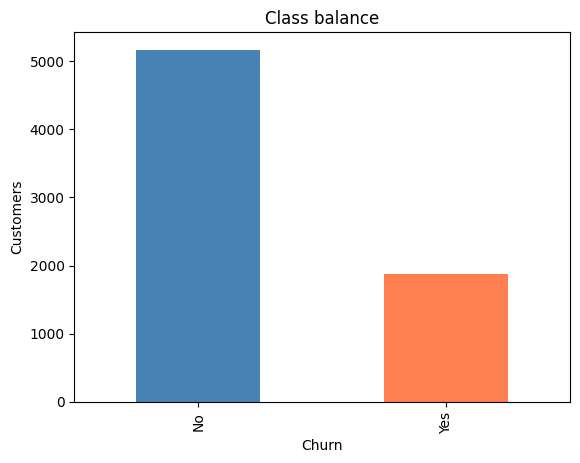

In [ ]:
df["Churn"].value_counts().plot(
    kind="bar", color=["steelblue", "coral"],
    title="Class balance", ylabel="Customers"
)
plt.show()

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values in TotalCharges:", df["TotalCharges"].isna().sum())


df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

Missing values in TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


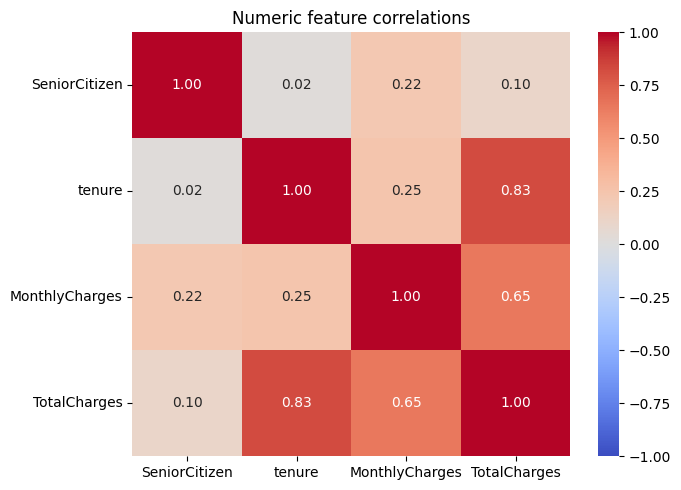

In [ ]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Numeric feature correlations")
plt.tight_layout()
plt.show()

## 2: Preprocessing

In [ ]:
# Drop the rows which have null values for "Total Charges" column
df = df.dropna(subset=["TotalCharges"])

# Target column Yes/No -> 1/0
y = (df["Churn"] == "Yes").astype(int)

# Remove the target column and customer ID from the features
X = df.drop(columns=["Churn", "customerID"])




In [ ]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,                 # Keep the same class distribution
    random_state=RANDOM_STATE
)

In [ ]:
# Numerical columns
numeric_columns = (
    X_train_raw
    .select_dtypes(include="number")
    .columns
    .tolist()
)

# Everything else is categorical
categorical_columns = (
    X_train_raw
    .select_dtypes(exclude="number")
    .columns
    .tolist()
)


In [ ]:
encoder = OneHotEncoder(
    handle_unknown="ignore",    # Ignore categories seen only in the test set
    sparse_output=False          # Return a NumPy array instead of a sparse matrix
)


# Learn the categories from training data
encoder.fit(X_train_raw[categorical_columns])




def encode_features(data):

    # Convert categorical columns into one-hot encoded columns
    encoded_array = encoder.transform(
        data[categorical_columns]
    )

    # Convert NumPy array to DataFrame
    encoded_df = pd.DataFrame(
        encoded_array,
        columns=encoder.get_feature_names_out(categorical_columns),
        index=data.index
    )

    # Keep the numerical columns
    numeric_df = data[numeric_columns]

    # Combine numerical and encoded categorical columns
    final_df = pd.concat(
        [numeric_df, encoded_df],
        axis=1
    )

    return final_df



X_train = encode_features(X_train_raw)
X_test = encode_features(X_test_raw)


feature_names = X_train.columns

print(f"Total features after encoding : {X_train.shape[1]}")

print(f"Training samples : {X_train.shape[0]}")
print(f"Testing samples  : {X_test.shape[0]}")

print(f"Training churn rate : {y_train.mean():.3f}")
print(f"Testing churn rate  : {y_test.mean():.3f}")

Total features after encoding : 45
Training samples : 5625
Testing samples  : 1407
Training churn rate : 0.266
Testing churn rate  : 0.266


### Evaluation Helper

This helper does one job:
print the "Churn" class metrics for **train and test side by side** (so the overfitting gap is
obvious).

In [ ]:
results = {}   # filled as we go

def evaluate(name, model):
    """Print train vs test metrics for the 'Churn' class and store the scores.
    The model must already be fitted (we fit it in its own cell)."""
    yhat_tr, yhat_te = model.predict(X_train), model.predict(X_test)

    def block(yt, yp):
        return (accuracy_score(yt, yp), precision_score(yt, yp),
                recall_score(yt, yp), f1_score(yt, yp,))

    tr, te = block(y_train, yhat_tr), block(y_test, yhat_te)

    print(f"  {name}")
    print(f"  {'metric':<12}{'train':>8}{'test':>8}")
    for lbl, i in [("Accuracy", 0), ("Precision", 1), ("Recall", 2), ("F1 (Churn)", 3)]:
        print(f"  {lbl:<12}{tr[i]:>8.3f}{te[i]:>8.3f}")
    print(f"  {'F1 gap':<12}{'':>8}{tr[3] - te[3]:>8.3f}")

    results[name] = {"model": model, "y_pred_test": yhat_te,
                     "train_f1": tr[3], "test_f1": te[3],
                     "train_acc": tr[0], "test_acc": te[0], "test_recall": te[2]}
    return model

## 3: Baseline — Decision Tree

**How it works.** A decision tree splits the data one feature at a time. At each node it searches
every feature for the split that best separates churners from stayers (measured by *Gini impurity*
or entropy), then repeats on each side. Left unconstrained, it keeps splitting until the leaves are
almost pure.


### First, a picture: what is *Gini impurity*?

A decision tree splits customers into groups and wants each group to be as **"pure"** as possible,
ideally all churn or all stay. *Gini impurity* is simply a score for **how mixed a group is.**

**The intuition.** Picture each group as a bag of marbles: 🔵 = a customer who *stays*, 🔴 = a
customer who *churns*. Reach in, grab one at random, and guess its label according to the bag's mix.
Gini impurity is **how often that guess is wrong**:

A bag that is **all one colour** → you're never surprised → **Gini = 0** (perfectly pure).

A **50 / 50** bag → you're wrong as often as right → **Gini = 0.5** (the worst case for two classes).

<div align="center">

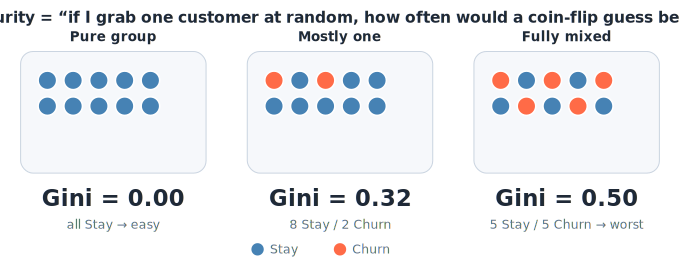

</div>


Formally, for classes with proportions $p_i$: $\;\text{Gini} = 1 - \sum_i p_i^2$. A split is
**good** when its child groups have *lower* Gini than the parent i.e. it sorts churners away from
stayers. At every node the tree tries each feature and threshold and keeps the split that drops
impurity the most.

In [ ]:
dt = DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
evaluate("Decision Tree (unconstrained)", dt)

  Decision Tree (unconstrained)
  metric         train    test
  Accuracy       0.998   0.721
  Precision      0.995   0.476
  Recall         0.999   0.511
  F1 (Churn)     0.997   0.493
  F1 gap                 0.504


DecisionTreeClassifier(class_weight='balanced', random_state=42)

### Another way to score a mix: *Entropy*

Gini isn't the only way to measure how mixed a group is. **Entropy** comes from information theory
and asks a slightly different question about the same bag of marbles:

> *"How surprised will I be, on average, when I find out the label of a customer I pull out?"*

A bag that is **all one colour** → no surprise at all → **Entropy = 0** (perfectly pure).

A **50 / 50** bag → maximum uncertainty, a true toss-up → **Entropy = 1** (the worst case for two classes).

Formally, for classes with proportions $p_i$:

$$\text{Entropy} = -\sum_i p_i \log_2 p_i$$

(with the convention $0 \cdot \log_2 0 = 0$, so a missing class adds nothing). Entropy is measured in *bits*:
it is the average number of yes/no questions you need to pin down a customer's label.

**The same three bags, scored both ways:**

| Bag | Mix | Gini | Entropy |
|-----|-----|------|---------|
| Pure group  | 10 Stay / 0 Churn | 0.00 | 0.00 |
| Mostly one  | 8 Stay / 2 Churn  | 0.32 | 0.72 |
| Fully mixed | 5 Stay / 5 Churn  | 0.50 | 1.00 |

Worked example for the "Mostly one" bag:

$$-(0.8 \log_2 0.8 + 0.2 \log_2 0.2) = -(0.8 \times -0.322 + 0.2 \times -2.322) = 0.258 + 0.464 \approx 0.72$$

**Information gain.** A tree using entropy picks the split with the biggest **information gain**.
That is the parent's entropy minus the *weighted average* entropy of its children (each child is
weighted by its share of the customers):

$$\text{Gain} = H(\text{parent}) - \sum_{\text{child}} \frac{n_{\text{child}}}{n_{\text{parent}}}\, H(\text{child})$$

For example, our full training set is about 26.5% churners, so the root node starts at
$H \approx 0.83$ bits (Gini $\approx 0.39$). Every split tries to bring that number down.


In [ ]:
dt_entropy = DecisionTreeClassifier(criterion = "entropy", class_weight="balanced", random_state=RANDOM_STATE)
dt_entropy.fit(X_train, y_train)
evaluate("Decision Tree (unconstrained)", dt_entropy)

  Decision Tree (unconstrained)
  metric         train    test
  Accuracy       0.998   0.728
  Precision      0.995   0.488
  Recall         0.999   0.492
  F1 (Churn)     0.997   0.490
  F1 gap                 0.507


DecisionTreeClassifier(class_weight='balanced', criterion='entropy',
                       random_state=42)

## Why `class_weight="balanced"`?

Look at the **"Mostly one"** group above: 8 Stay, 2 Churn, Gini = 0.32.

A tree trained on data like this has an easy shortcut just keep predicting
**Stay** and it's right 80% of the time. The 2 Churn customers barely move the
impurity, so the tree has little incentive to work hard to separate them. But
those churners are usually the whole reason we built the model.

`class_weight="balanced"` fixes this by making the **rare class count for more**.

### What it actually computes

sklearn sets each class weight inversely proportional to how often it appears:

$$w_c = \frac{n_{\text{samples}}}{n_{\text{classes}} \times n_c}$$

For our 8-Stay / 2-Churn node (10 samples, 2 classes):

| Class | Count | Weight $w_c$ | Effective count |
|-------|-------|--------------|-----------------|
| Stay  | 8     | 10 / (2×8) = **0.625** | 8 × 0.625 = **5** |
| Churn | 2     | 10 / (2×2) = **2.50**  | 2 × 2.50 = **5** |

Each Churn example now carries **4× the weight** of a Stay example.

### The connection to Gini

The tree computes impurity from these *weighted* counts, not the raw ones.
So after balancing, the node effectively looks like **5 Stay / 5 Churn**:

$$\text{Gini} = 1 - (0.5^2 + 0.5^2) = 0.50$$



To *see* what a tree does, here are the top few levels of a shallow tree (full depth would be
unreadable). Each box is a yes/no question; colour shows which class dominates the customers that
land there.

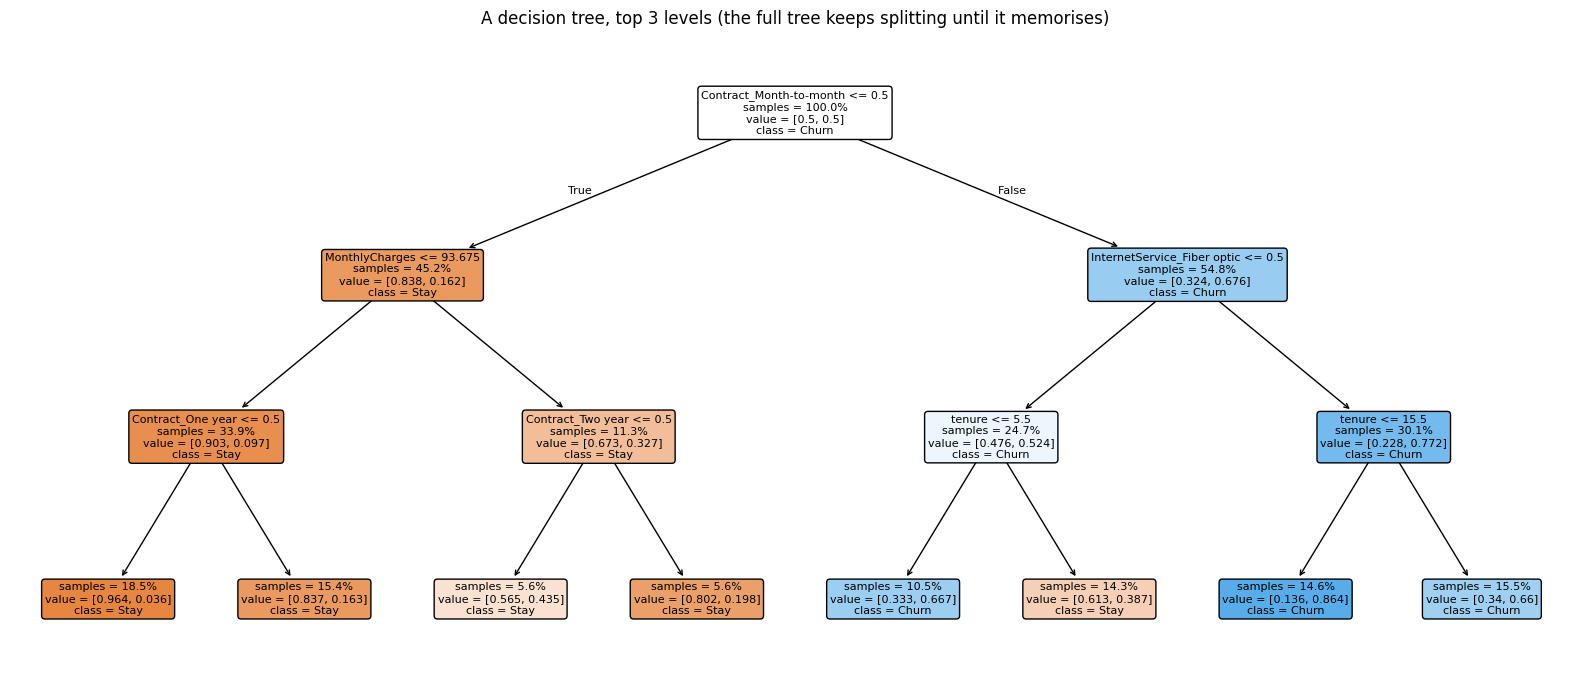

In [ ]:
demo_tree = DecisionTreeClassifier(class_weight = "balanced", max_depth = 3, random_state=RANDOM_STATE).fit(X_train, y_train)
plt.figure(figsize=(16, 7))
plot_tree(demo_tree, feature_names=feature_names, class_names=["Stay", "Churn"],
          filled=True, rounded=True, fontsize=8, impurity=False, proportion=True)
plt.title("A decision tree, top 3 levels (the full tree keeps splitting until it memorises)")
plt.tight_layout()
plt.show()

## 4: Bagging — Averaging Away the Variance

**How it works.** *Bagging* (Bootstrap Aggregating) draws many bootstrap samples new training
sets of the same size, sampled **with replacement** fits an independent tree on each, and
**averages their votes**. Each tree still overfits its own sample, but their mistakes are only
partly correlated, so averaging cancels much of the noise.

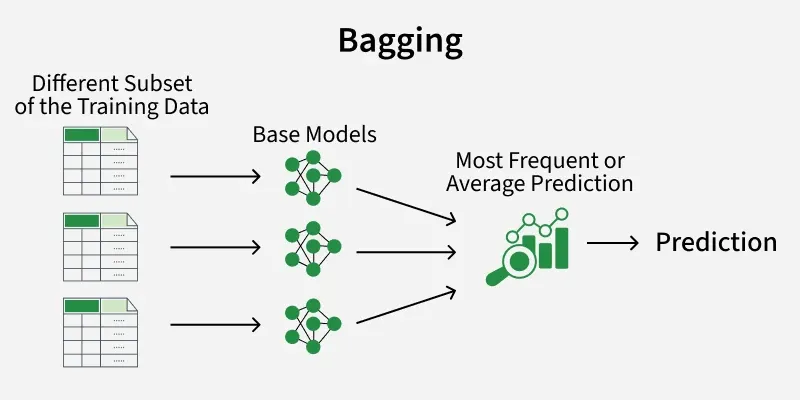







In [ ]:
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(min_samples_split=10, class_weight="balanced", random_state=RANDOM_STATE),
    n_estimators=200,
    max_samples=0.7,
    bootstrap=True,
    random_state=RANDOM_STATE,
)
bag.fit(X_train, y_train)
evaluate("Bagging (200 trees)", bag)

  Bagging (200 trees)
  metric         train    test
  Accuracy       0.922   0.778
  Precision      0.836   0.580
  Recall         0.880   0.602
  F1 (Churn)     0.858   0.591
  F1 gap                 0.267


BaggingClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                   min_samples_split=10,
                                                   random_state=42),
                  max_samples=0.7, n_estimators=200, random_state=42)

### Random Forest — bagging with decorrelated trees

**How it works.** A *Random Forest* is bagging plus one extra idea: at **each split**, a tree may
only consider a **random subset of the features** (often about $\sqrt{p}$ of them). This stops
every tree from leaning on the same one or two dominant predictors here, contract type and tenure so the trees **disagree more**.

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    min_samples_split=10,
    random_state=RANDOM_STATE,
)
rf.fit(X_train, y_train)
evaluate("Random Forest", rf)

  Random Forest
  metric         train    test
  Accuracy       0.895   0.774
  Precision      0.753   0.563
  Recall         0.900   0.666
  F1 (Churn)     0.820   0.610
  F1 gap                 0.209


RandomForestClassifier(class_weight='balanced', min_samples_split=10,
                       n_estimators=200, random_state=42)

## Summary

A single unconstrained tree **memorised** the training data near perfect train F1, weak test F1
because of its **high variance**.

**Bagging** (Bagging, Random Forest) trains many trees **in parallel** on bootstrap samples and
  **averages** them. This reduces **variance**: train F1 drops off its ceiling, test F1 rises, and
  the train/test gap collapses. Random Forest decorrelates the trees further with random feature
  subsets.

